NOTEBOOK 12: REAL-WORLD BUSINESS-ORIENTED VALIDATION

Configuration:
Random State: 42
Test Size: 0.2
Decision Threshold: 0.21
False Negative Cost: 5
False Positive Cost: 1

DATASET OVERVIEW

Dataset Shape: (10000, 45)

Missing Values:
0

Duplicate Rows:
0

TARGET DISTRIBUTION
 Class  Count  Percentage
     0   8979       89.79
     1   1021       10.21

FEATURE AND TARGET PREPARATION

Feature Matrix Shape: (10000, 44)
Target Shape: (10000,)
Number of Predictors: 44

STRATIFIED TRAIN / TEST SPLIT

Training Set: (8000, 44)
Testing Set:  (2000, 44)

Training Target Distribution:
churn
0    7183
1     817
Name: count, dtype: int64

Testing Target Distribution:
churn
0    1796
1     204
Name: count, dtype: int64

✓ Test set matches the previously defined 80/20 stratified split.

FINAL COST-SENSITIVE MODEL

Model Path: cost_sensitive_model_results/Best_Cost_Sensitive_XGBoost.pkl
Model Type: <class 'imblearn.pipeline.Pipeline'>

Pipeline Components:
  preprocessing: ColumnTransformer
  smote:

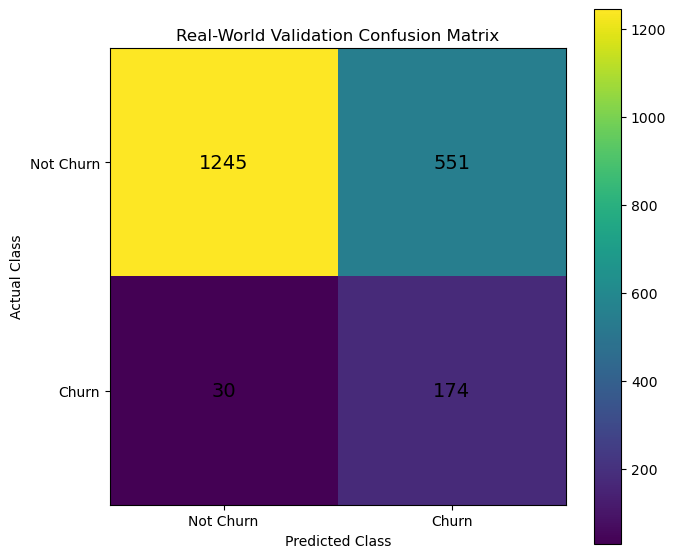


RISK GROUP VALIDATION
risk_group  customers  actual_churners  observed_churn_rate  mean_predicted_probability  predicted_churners  churn_capture_rate  precision
       Low        762               15             1.968504                    7.658888                   0            7.352941        NaN
  Moderate        513               15             2.923977                   12.928460                   0            7.352941        NaN
      High        396               81            20.454545                   32.183998                 396           39.705882  20.454545
 Very High        329               93            28.267477                   50.388336                 329           45.588235  28.267477


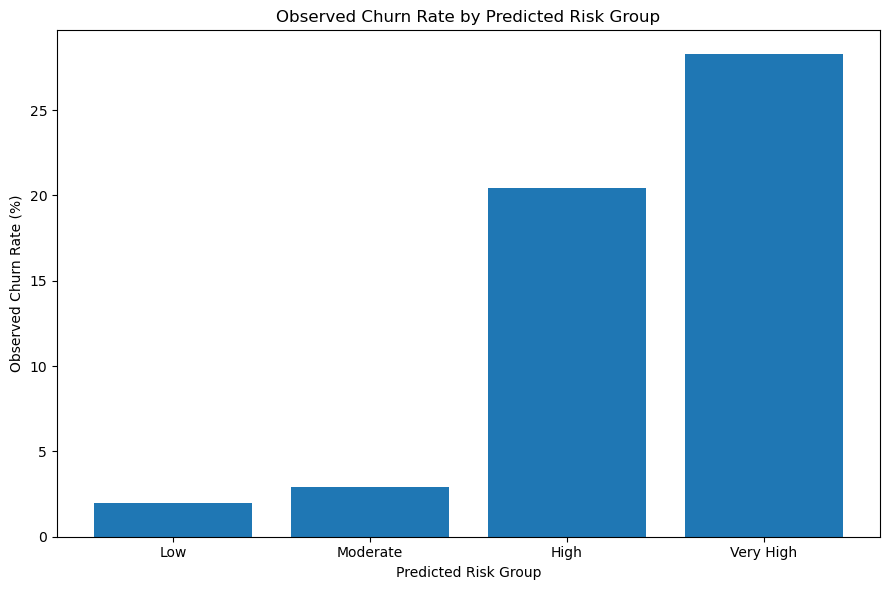


RISK DECILE VALIDATION
 risk_decile  customers  actual_churners  observed_churn_rate  mean_predicted_probability  capture_rate     lift
           1        200               63                 31.5                   55.297775     30.882353 3.088235
           2        200               39                 19.5                   41.447414     19.117647 1.911765
           3        200               48                 24.0                   33.823025     23.529412 2.352941
           4        200               27                 13.5                   22.738951     13.235294 1.323529
           5        200                5                  2.5                   13.433762      2.450980 0.245098
           6        200                7                  3.5                   11.101147      3.431373 0.343137
           7        200                3                  1.5                    9.625852      1.470588 0.147059
           8        200                3                  1.5           

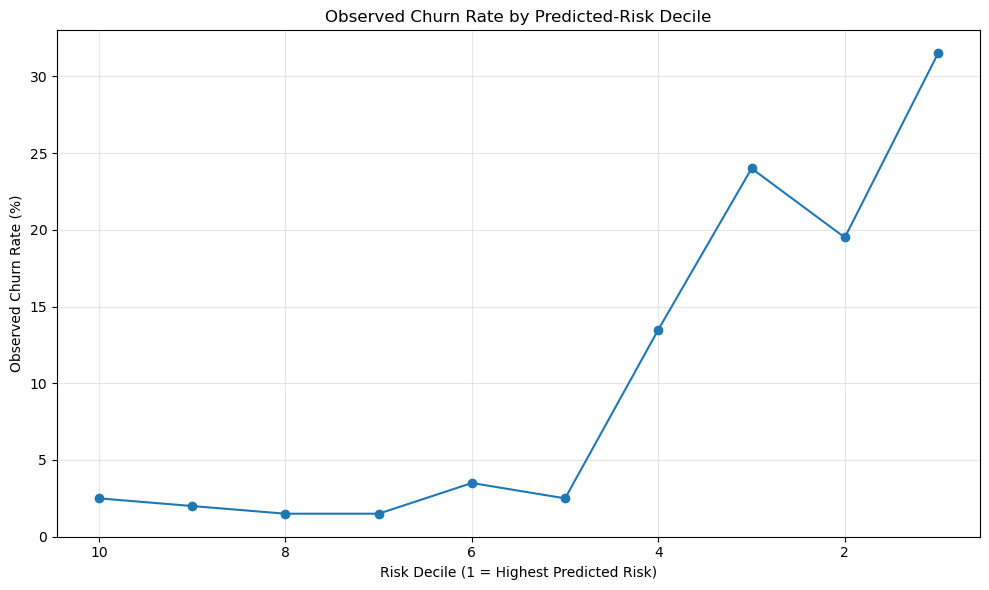


RETENTION TARGETING VALIDATION
 Targeting_Percentage  Customers_Targeted  Actual_Churners_Captured  False_Positives  Precision  Churn_Capture_Rate     Lift
                   10                 200                        63              137  31.500000           30.882353 3.088235
                   20                 400                       102              298  25.500000           50.000000 2.500000
                   30                 600                       150              450  25.000000           73.529412 2.450980
                   40                 800                       177              623  22.125000           86.764706 2.169118
                   50                1000                       182              818  18.200000           89.215686 1.784314
                   60                1200                       189             1011  15.750000           92.647059 1.544118
                   70                1400                       192             1208  13.7142

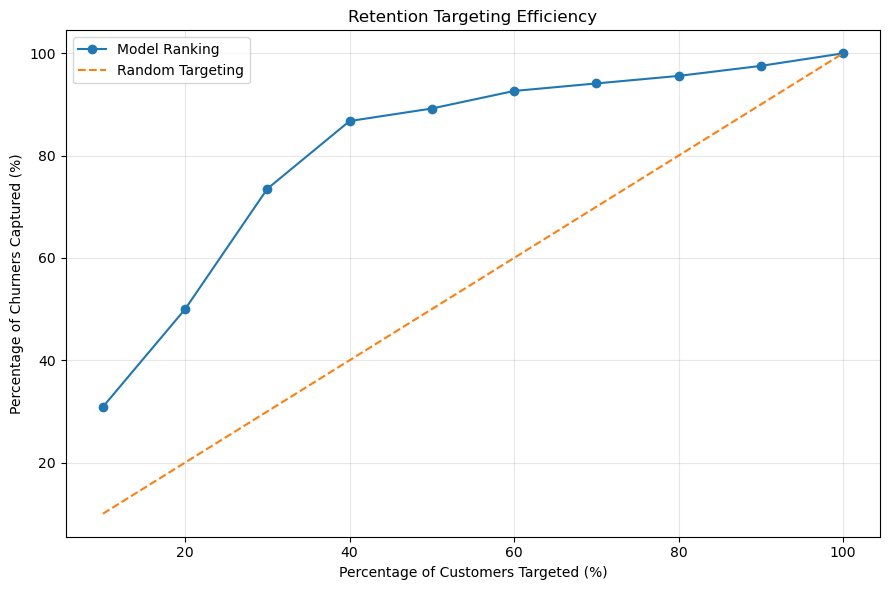


TOP 10% RETENTION PRIORITISATION

Customers in Top 10%: 200
Actual Churners Captured: 63
Churn Capture Rate: 30.88%
Precision: 31.50%
Lift: 3.09

CUSTOMER SEGMENT VALIDATION
customer_segment  customers  actual_churners  observed_churn_rate  predicted_churners  precision    recall  f1_score  roc_auc  mean_predicted_probability
      enterprise        166               15             9.036145                  51  23.529412 80.000000 36.363636 0.789845                   18.230320
      individual       1212              126            10.396040                 440  25.000000 87.301587 38.869258 0.793468                   20.392891
             sme        622               63            10.128617                 234  22.222222 82.539683 35.016835 0.803902                   22.586145

CONTRACT TYPE VALIDATION
contract_type  customers  actual_churners  observed_churn_rate  predicted_churners  precision    recall  f1_score  roc_auc  mean_predicted_probability
      monthly       1008        

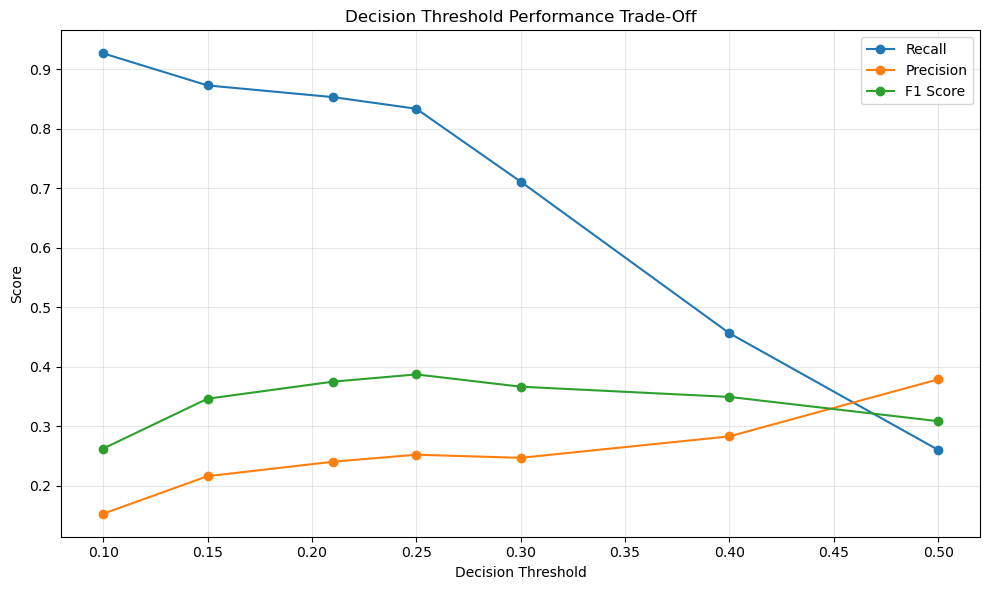

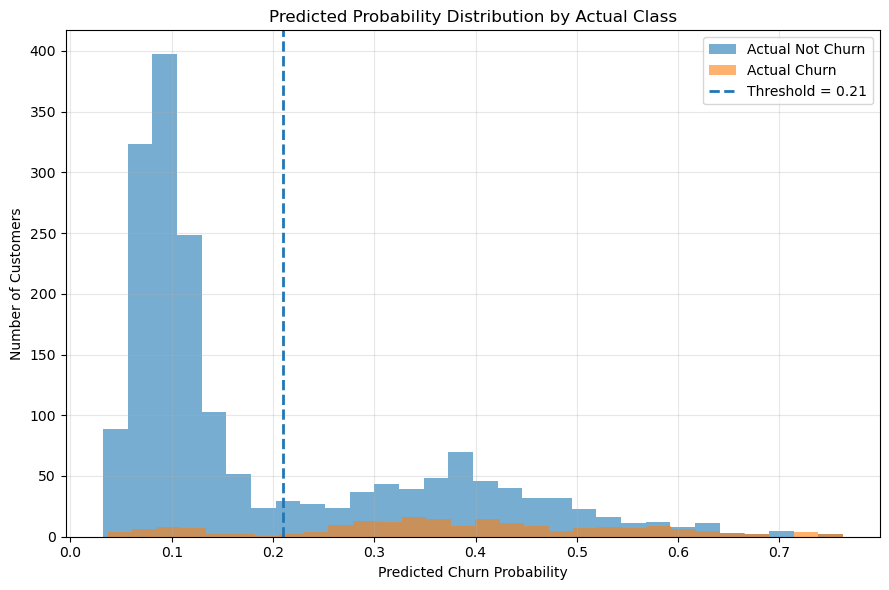

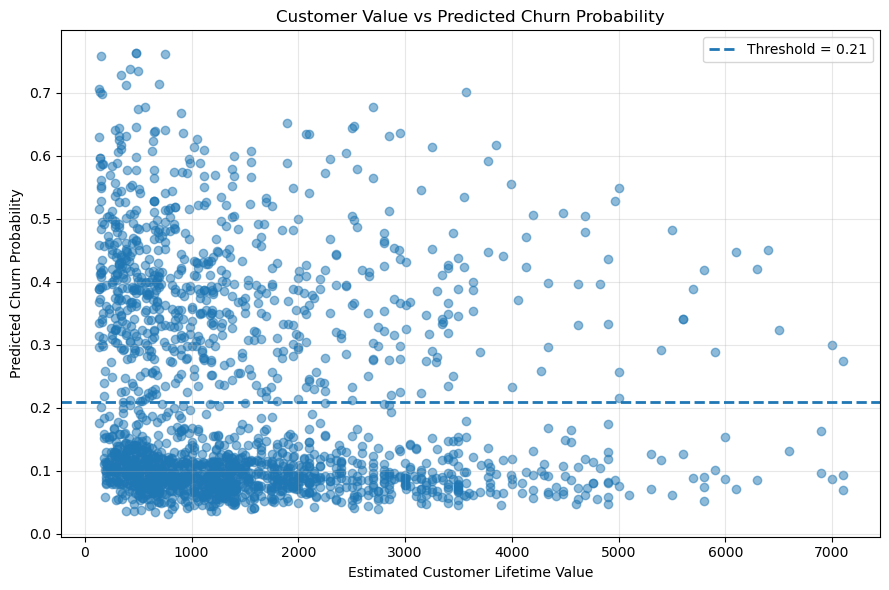

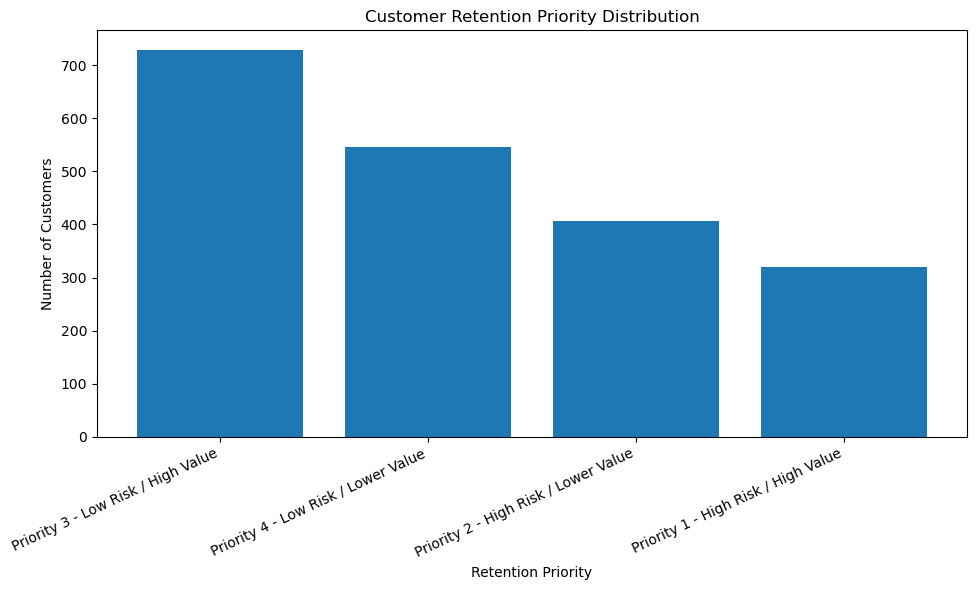


RETENTION ACTION PRIORITIES
 predicted_probability  predicted_churn  actual_churn risk_group prediction_result customer_segment contract_type  csat_score  monthly_fee  estimated_clv  tenure_months  monthly_logins  last_login_days_ago  support_tickets  nps_score  payment_failures  engagement_score                   retention_priority               recommended_action
              0.762697                1             0  Very High    False Positive              sme       monthly           4         30.0          480.0              4               4                    5                1          7                 1               3.1 Priority 2 - High Risk / Lower Value Immediate Retention Intervention
              0.762582                1             1  Very High     True Positive       individual       monthly           3         30.0          480.0              4               0                   16                1         76                 1               2.7 Priority 2 - High Ris

In [1]:
# ============================================================
# Notebook 12: Real-World Business-Oriented Validation
# Hybrid Interpretable Machine Learning Model for Customer Churn
# ============================================================


# ============================================================
# Libraries
# ============================================================

import os
import joblib
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)


# ============================================================
# Configuration
# ============================================================

RANDOM_STATE = 42
TEST_SIZE = 0.20

# Fixed threshold selected in Notebook 10
THRESHOLD = 0.21

# Business-cost assumptions
# These are hypothetical methodological assumptions.
FALSE_NEGATIVE_COST = 5
FALSE_POSITIVE_COST = 1

# Output directory
OUTPUT_DIR = "real_world_validation_results"

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# ============================================================
# Dataset and Model Paths
# ============================================================

DATA_PATH = "customer_churn_feature_engineered.csv"

MODEL_PATH = (
    "cost_sensitive_model_results/"
    "Best_Cost_Sensitive_XGBoost.pkl"
)


print("=" * 70)
print("NOTEBOOK 12: REAL-WORLD BUSINESS-ORIENTED VALIDATION")
print("=" * 70)

print("\nConfiguration:")
print(f"Random State: {RANDOM_STATE}")
print(f"Test Size: {TEST_SIZE}")
print(f"Decision Threshold: {THRESHOLD}")
print(
    f"False Negative Cost: {FALSE_NEGATIVE_COST}"
)
print(
    f"False Positive Cost: {FALSE_POSITIVE_COST}"
)


# ============================================================
# Load Dataset
# ============================================================

CustomerData_Df = pd.read_csv(
    DATA_PATH
)

print("\n" + "=" * 70)
print("DATASET OVERVIEW")
print("=" * 70)

print(
    f"\nDataset Shape: "
    f"{CustomerData_Df.shape}"
)

print(
    "\nMissing Values:"
)

print(
    CustomerData_Df.isnull().sum().sum()
)

print(
    "\nDuplicate Rows:"
)

print(
    CustomerData_Df.duplicated().sum()
)


# ============================================================
# Target Distribution
# ============================================================

print("\n" + "=" * 70)
print("TARGET DISTRIBUTION")
print("=" * 70)

target_counts = (
    CustomerData_Df["churn"]
    .value_counts()
    .sort_index()
)

target_percentages = (
    CustomerData_Df["churn"]
    .value_counts(
        normalize=True
    )
    .sort_index()
    * 100
)

target_distribution = pd.DataFrame({
    "Class": target_counts.index,
    "Count": target_counts.values,
    "Percentage": target_percentages.values
})

print(
    target_distribution.to_string(
        index=False
    )
)

target_distribution.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Target_Distribution.csv"
    ),
    index=False
)


# ============================================================
# Prepare Features and Target
# ============================================================

# Customer ID is an identifier and is not used
# as a predictive feature.

feature_drop_columns = [
    "churn"
]

if "customer_id" in CustomerData_Df.columns:

    feature_drop_columns.append(
        "customer_id"
    )

X = CustomerData_Df.drop(
    columns=feature_drop_columns
)

y = CustomerData_Df["churn"]


print("\n" + "=" * 70)
print("FEATURE AND TARGET PREPARATION")
print("=" * 70)

print(
    f"\nFeature Matrix Shape: {X.shape}"
)

print(
    f"Target Shape: {y.shape}"
)

print(
    f"Number of Predictors: {X.shape[1]}"
)


# ============================================================
# Recreate Train/Test Split
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE
)


print("\n" + "=" * 70)
print("STRATIFIED TRAIN / TEST SPLIT")
print("=" * 70)

print(
    f"\nTraining Set: {X_train.shape}"
)

print(
    f"Testing Set:  {X_test.shape}"
)

print(
    "\nTraining Target Distribution:"
)

print(
    y_train.value_counts()
    .sort_index()
)

print(
    "\nTesting Target Distribution:"
)

print(
    y_test.value_counts()
    .sort_index()
)


# ============================================================
# Validate Test Set
# ============================================================

assert len(X_test) == 2000, (
    "Unexpected test-set size."
)

assert y_test.sum() == 204, (
    "Unexpected number of churners "
    "in the test set."
)

print(
    "\n✓ Test set matches the previously "
    "defined 80/20 stratified split."
)


# ============================================================
# Load Final Cost-Sensitive Model
# ============================================================

final_model = joblib.load(
    MODEL_PATH
)

print("\n" + "=" * 70)
print("FINAL COST-SENSITIVE MODEL")
print("=" * 70)

print(
    f"\nModel Path: {MODEL_PATH}"
)

print(
    f"Model Type: {type(final_model)}"
)

print(
    "\nPipeline Components:"
)

for step_name, step_object in (
    final_model.named_steps.items()
):

    print(
        f"  {step_name}: "
        f"{type(step_object).__name__}"
    )


# ============================================================
# Generate Test Probabilities
# ============================================================

# The complete saved pipeline is used for prediction.
#
# IMPORTANT:
# No manual SMOTE is applied to the test set.
# The pipeline performs preprocessing and prediction
# without modifying the test distribution.

test_probabilities = (
    final_model.predict_proba(
        X_test
    )[:, 1]
)


# ============================================================
# Apply Fixed Decision Threshold
# ============================================================

test_predictions = (
    test_probabilities >= THRESHOLD
).astype(int)


print("\n" + "=" * 70)
print("MODEL PREDICTIONS")
print("=" * 70)

print(
    f"\nMinimum Predicted Probability: "
    f"{test_probabilities.min():.4f}"
)

print(
    f"Maximum Predicted Probability: "
    f"{test_probabilities.max():.4f}"
)

print(
    f"Mean Predicted Probability: "
    f"{test_probabilities.mean():.4f}"
)

print(
    f"\nPredicted Not Churn: "
    f"{(test_predictions == 0).sum()}"
)

print(
    f"Predicted Churn: "
    f"{(test_predictions == 1).sum()}"
)


# ============================================================
# Create Validation DataFrame
# ============================================================

Validation_Df = X_test.copy()

Validation_Df["actual_churn"] = (
    y_test.values
)

Validation_Df["predicted_probability"] = (
    test_probabilities
)

Validation_Df["predicted_churn"] = (
    test_predictions
)

Validation_Df["threshold"] = (
    THRESHOLD
)

Validation_Df = (
    Validation_Df
    .reset_index(drop=True)
)


print("\nValidation Dataset Shape:")
print(
    Validation_Df.shape
)


# ============================================================
# Overall Validation Metrics
# ============================================================

accuracy = accuracy_score(
    y_test,
    test_predictions
)

precision = precision_score(
    y_test,
    test_predictions,
    zero_division=0
)

recall = recall_score(
    y_test,
    test_predictions,
    zero_division=0
)

f1 = f1_score(
    y_test,
    test_predictions,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    test_probabilities
)

average_precision = (
    average_precision_score(
        y_test,
        test_probabilities
    )
)

balanced_accuracy = (
    balanced_accuracy_score(
        y_test,
        test_predictions
    )
)

tn, fp, fn, tp = (
    confusion_matrix(
        y_test,
        test_predictions
    ).ravel()
)

specificity = (
    tn / (tn + fp)
)

business_cost = (
    fn * FALSE_NEGATIVE_COST
    + fp * FALSE_POSITIVE_COST
)


# ============================================================
# Overall Results Table
# ============================================================

Overall_Results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "Average Precision",
        "Balanced Accuracy",
        "Specificity",
        "True Negatives",
        "False Positives",
        "False Negatives",
        "True Positives",
        "Business Cost"
    ],
    "Value": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc,
        average_precision,
        balanced_accuracy,
        specificity,
        tn,
        fp,
        fn,
        tp,
        business_cost
    ]
})


print("\n" + "=" * 70)
print("OVERALL REAL-WORLD VALIDATION RESULTS")
print("=" * 70)

print(
    Overall_Results.to_string(
        index=False
    )
)

Overall_Results.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Overall_Real_World_Validation_Results.csv"
    ),
    index=False
)


# ============================================================
# Classification Report
# ============================================================

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

classification_report_text = (
    classification_report(
        y_test,
        test_predictions,
        target_names=[
            "Not Churn",
            "Churn"
        ],
        zero_division=0
    )
)

print(
    classification_report_text
)

with open(
    os.path.join(
        OUTPUT_DIR,
        "Real_World_Classification_Report.txt"
    ),
    "w"
) as file:

    file.write(
        classification_report_text
    )


# ============================================================
# Confusion Matrix
# ============================================================

Confusion_Matrix = confusion_matrix(
    y_test,
    test_predictions
)

plt.figure(
    figsize=(7, 6)
)

plt.imshow(
    Confusion_Matrix
)

plt.title(
    "Real-World Validation Confusion Matrix"
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "Actual Class"
)

plt.xticks(
    [0, 1],
    [
        "Not Churn",
        "Churn"
    ]
)

plt.yticks(
    [0, 1],
    [
        "Not Churn",
        "Churn"
    ]
)

for i in range(2):

    for j in range(2):

        plt.text(
            j,
            i,
            Confusion_Matrix[i, j],
            ha="center",
            va="center",
            fontsize=14
        )

plt.colorbar()

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Real_World_Validation_Confusion_Matrix.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# Risk Group Classification
# ============================================================

# IMPORTANT:
# These groups represent model-score ranges.
# They are NOT calibrated probability categories.

def assign_risk_group(
    probability
):

    if probability < 0.10:

        return "Low"

    elif probability < THRESHOLD:

        return "Moderate"

    elif probability < 0.40:

        return "High"

    else:

        return "Very High"


Validation_Df["risk_group"] = (
    Validation_Df[
        "predicted_probability"
    ]
    .apply(assign_risk_group)
)


risk_order = [
    "Low",
    "Moderate",
    "High",
    "Very High"
]

Validation_Df["risk_group"] = (
    pd.Categorical(
        Validation_Df["risk_group"],
        categories=risk_order,
        ordered=True
    )
)


# ============================================================
# Risk Group Validation
# ============================================================

Risk_Group_Validation = (
    Validation_Df
    .groupby(
        "risk_group",
        observed=False
    )
    .agg(
        customers=(
            "actual_churn",
            "size"
        ),
        actual_churners=(
            "actual_churn",
            "sum"
        ),
        observed_churn_rate=(
            "actual_churn",
            "mean"
        ),
        mean_predicted_probability=(
            "predicted_probability",
            "mean"
        ),
        predicted_churners=(
            "predicted_churn",
            "sum"
        )
    )
    .reset_index()
)

Risk_Group_Validation[
    "observed_churn_rate"
] *= 100

Risk_Group_Validation[
    "mean_predicted_probability"
] *= 100

Risk_Group_Validation[
    "churn_capture_rate"
] = (
    Risk_Group_Validation[
        "actual_churners"
    ]
    / y_test.sum()
    * 100
)

Risk_Group_Validation[
    "precision"
] = (
    Risk_Group_Validation[
        "actual_churners"
    ]
    / Risk_Group_Validation[
        "predicted_churners"
    ].replace(0, np.nan)
    * 100
)


print("\n" + "=" * 70)
print("RISK GROUP VALIDATION")
print("=" * 70)

print(
    Risk_Group_Validation.to_string(
        index=False
    )
)

Risk_Group_Validation.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Risk_Group_Validation.csv"
    ),
    index=False
)


# ============================================================
# Observed Churn Rate by Risk Group
# ============================================================

plt.figure(
    figsize=(9, 6)
)

plt.bar(
    Risk_Group_Validation[
        "risk_group"
    ].astype(str),
    Risk_Group_Validation[
        "observed_churn_rate"
    ]
)

plt.xlabel(
    "Predicted Risk Group"
)

plt.ylabel(
    "Observed Churn Rate (%)"
)

plt.title(
    "Observed Churn Rate by Predicted Risk Group"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Observed_Churn_Rate_by_Risk_Group.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# Risk Decile Validation
# ============================================================

Validation_Df["risk_decile"] = (
    pd.qcut(
        Validation_Df[
            "predicted_probability"
        ],
        q=10,
        labels=False,
        duplicates="drop"
    )
)

# Reverse ordering:
# 1 = highest predicted-risk decile
# 10 = lowest predicted-risk decile

maximum_decile = (
    Validation_Df[
        "risk_decile"
    ].max()
)

Validation_Df["risk_decile"] = (
    maximum_decile
    + 1
    - Validation_Df[
        "risk_decile"
    ]
)


# ============================================================
# Decile Summary
# ============================================================

Risk_Decile_Validation = (
    Validation_Df
    .groupby(
        "risk_decile"
    )
    .agg(
        customers=(
            "actual_churn",
            "size"
        ),
        actual_churners=(
            "actual_churn",
            "sum"
        ),
        observed_churn_rate=(
            "actual_churn",
            "mean"
        ),
        mean_predicted_probability=(
            "predicted_probability",
            "mean"
        )
    )
    .reset_index()
    .sort_values(
        "risk_decile"
    )
)

Risk_Decile_Validation[
    "observed_churn_rate"
] *= 100

Risk_Decile_Validation[
    "mean_predicted_probability"
] *= 100

Risk_Decile_Validation[
    "capture_rate"
] = (
    Risk_Decile_Validation[
        "actual_churners"
    ]
    / y_test.sum()
    * 100
)

overall_churn_rate = (
    y_test.mean()
)

Risk_Decile_Validation[
    "lift"
] = (
    (
        Risk_Decile_Validation[
            "observed_churn_rate"
        ]
        / 100
    )
    / overall_churn_rate
)


print("\n" + "=" * 70)
print("RISK DECILE VALIDATION")
print("=" * 70)

print(
    Risk_Decile_Validation.to_string(
        index=False
    )
)

Risk_Decile_Validation.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Risk_Decile_Validation.csv"
    ),
    index=False
)


# ============================================================
# Risk Decile Churn Rate Plot
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    Risk_Decile_Validation[
        "risk_decile"
    ],
    Risk_Decile_Validation[
        "observed_churn_rate"
    ],
    marker="o"
)

plt.xlabel(
    "Risk Decile "
    "(1 = Highest Predicted Risk)"
)

plt.ylabel(
    "Observed Churn Rate (%)"
)

plt.title(
    "Observed Churn Rate by Predicted-Risk Decile"
)

plt.gca().invert_xaxis()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Observed_Churn_Rate_by_Risk_Decile.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# Retention Targeting Analysis
# ============================================================

# Customers are ranked from highest to lowest
# predicted churn probability.

Ranking_Df = (
    Validation_Df
    .sort_values(
        "predicted_probability",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

targeting_percentages = [
    10,
    20,
    30,
    40,
    50,
    60,
    70,
    80,
    90,
    100
]

targeting_results = []

total_churners = (
    Ranking_Df[
        "actual_churn"
    ].sum()
)


for percentage in targeting_percentages:

    number_to_target = int(
        np.ceil(
            len(Ranking_Df)
            * percentage
            / 100
        )
    )

    targeted_customers = (
        Ranking_Df.iloc[
            :number_to_target
        ]
    )

    captured_churners = (
        targeted_customers[
            "actual_churn"
        ].sum()
    )

    false_positives = (
        number_to_target
        - captured_churners
    )

    target_precision = (
        captured_churners
        / number_to_target
    )

    churn_capture_rate = (
        captured_churners
        / total_churners
    )

    lift = (
        target_precision
        / overall_churn_rate
    )

    targeting_results.append({
        "Targeting_Percentage": percentage,
        "Customers_Targeted": number_to_target,
        "Actual_Churners_Captured": (
            captured_churners
        ),
        "False_Positives": (
            false_positives
        ),
        "Precision": target_precision,
        "Churn_Capture_Rate": (
            churn_capture_rate
        ),
        "Lift": lift
    })


Retention_Targeting = pd.DataFrame(
    targeting_results
)

Retention_Targeting[
    "Precision"
] *= 100

Retention_Targeting[
    "Churn_Capture_Rate"
] *= 100


print("\n" + "=" * 70)
print("RETENTION TARGETING VALIDATION")
print("=" * 70)

print(
    Retention_Targeting.to_string(
        index=False
    )
)

Retention_Targeting.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Retention_Targeting_Analysis.csv"
    ),
    index=False
)


# ============================================================
# Retention Targeting Efficiency Plot
# ============================================================

plt.figure(
    figsize=(9, 6)
)

plt.plot(
    Retention_Targeting[
        "Targeting_Percentage"
    ],
    Retention_Targeting[
        "Churn_Capture_Rate"
    ],
    marker="o"
)

plt.plot(
    Retention_Targeting[
        "Targeting_Percentage"
    ],
    Retention_Targeting[
        "Targeting_Percentage"
    ],
    linestyle="--"
)

plt.xlabel(
    "Percentage of Customers Targeted (%)"
)

plt.ylabel(
    "Percentage of Churners Captured (%)"
)

plt.title(
    "Retention Targeting Efficiency"
)

plt.legend(
    [
        "Model Ranking",
        "Random Targeting"
    ]
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Retention_Targeting_Efficiency.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# Top 10% Retention Analysis
# ============================================================

top_10_count = int(
    np.ceil(
        len(Ranking_Df) * 0.10
    )
)

top_10_customers = (
    Ranking_Df.iloc[
        :top_10_count
    ]
)

top_10_churners = (
    top_10_customers[
        "actual_churn"
    ].sum()
)

top_10_capture_rate = (
    top_10_churners
    / total_churners
    * 100
)

top_10_precision = (
    top_10_churners
    / top_10_count
    * 100
)

top_10_lift = (
    top_10_precision
    / (overall_churn_rate * 100)
)


print("\n" + "=" * 70)
print("TOP 10% RETENTION PRIORITISATION")
print("=" * 70)

print(
    f"\nCustomers in Top 10%: "
    f"{top_10_count}"
)

print(
    f"Actual Churners Captured: "
    f"{top_10_churners}"
)

print(
    f"Churn Capture Rate: "
    f"{top_10_capture_rate:.2f}%"
)

print(
    f"Precision: "
    f"{top_10_precision:.2f}%"
)

print(
    f"Lift: "
    f"{top_10_lift:.2f}"
)


# ============================================================
# Customer Segment Validation
# ============================================================

if "customer_segment" in Validation_Df.columns:

    Segment_Results = []

    for segment, group in (
        Validation_Df
        .groupby(
            "customer_segment",
            observed=False
        )
    ):

        actual = (
            group["actual_churn"]
        )

        predicted = (
            group["predicted_churn"]
        )

        probabilities = (
            group[
                "predicted_probability"
            ]
        )

        if actual.nunique() > 1:

            segment_auc = (
                roc_auc_score(
                    actual,
                    probabilities
                )
            )

        else:

            segment_auc = np.nan

        Segment_Results.append({
            "customer_segment": segment,
            "customers": len(group),
            "actual_churners": actual.sum(),
            "observed_churn_rate": (
                actual.mean() * 100
            ),
            "predicted_churners": (
                predicted.sum()
            ),
            "precision": (
                precision_score(
                    actual,
                    predicted,
                    zero_division=0
                ) * 100
            ),
            "recall": (
                recall_score(
                    actual,
                    predicted,
                    zero_division=0
                ) * 100
            ),
            "f1_score": (
                f1_score(
                    actual,
                    predicted,
                    zero_division=0
                ) * 100
            ),
            "roc_auc": segment_auc,
            "mean_predicted_probability": (
                probabilities.mean() * 100
            )
        })

    Segment_Validation = pd.DataFrame(
        Segment_Results
    )

    print("\n" + "=" * 70)
    print("CUSTOMER SEGMENT VALIDATION")
    print("=" * 70)

    print(
        Segment_Validation.to_string(
            index=False
        )
    )

    Segment_Validation.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "Customer_Segment_Validation.csv"
        ),
        index=False
    )


# ============================================================
# Contract Type Validation
# ============================================================

if "contract_type" in Validation_Df.columns:

    Contract_Results = []

    for contract, group in (
        Validation_Df
        .groupby(
            "contract_type",
            observed=False
        )
    ):

        actual = (
            group["actual_churn"]
        )

        predicted = (
            group["predicted_churn"]
        )

        probabilities = (
            group[
                "predicted_probability"
            ]
        )

        if actual.nunique() > 1:

            contract_auc = (
                roc_auc_score(
                    actual,
                    probabilities
                )
            )

        else:

            contract_auc = np.nan

        Contract_Results.append({
            "contract_type": contract,
            "customers": len(group),
            "actual_churners": actual.sum(),
            "observed_churn_rate": (
                actual.mean() * 100
            ),
            "predicted_churners": (
                predicted.sum()
            ),
            "precision": (
                precision_score(
                    actual,
                    predicted,
                    zero_division=0
                ) * 100
            ),
            "recall": (
                recall_score(
                    actual,
                    predicted,
                    zero_division=0
                ) * 100
            ),
            "f1_score": (
                f1_score(
                    actual,
                    predicted,
                    zero_division=0
                ) * 100
            ),
            "roc_auc": contract_auc,
            "mean_predicted_probability": (
                probabilities.mean() * 100
            )
        })

    Contract_Validation = pd.DataFrame(
        Contract_Results
    )

    print("\n" + "=" * 70)
    print("CONTRACT TYPE VALIDATION")
    print("=" * 70)

    print(
        Contract_Validation.to_string(
            index=False
        )
    )

    Contract_Validation.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "Contract_Type_Validation.csv"
        ),
        index=False
    )


# ============================================================
# Customer Satisfaction Validation
# ============================================================

if "csat_score" in Validation_Df.columns:

    Validation_Df[
        "satisfaction_group"
    ] = pd.cut(
        Validation_Df[
            "csat_score"
        ],
        bins=[
            0,
            2,
            3,
            4,
            5
        ],
        labels=[
            "Low Satisfaction",
            "Moderate Satisfaction",
            "High Satisfaction",
            "Very High Satisfaction"
        ],
        include_lowest=True
    )

    Satisfaction_Results = []

    for satisfaction, group in (
        Validation_Df
        .groupby(
            "satisfaction_group",
            observed=False
        )
    ):

        actual = (
            group["actual_churn"]
        )

        predicted = (
            group["predicted_churn"]
        )

        probabilities = (
            group[
                "predicted_probability"
            ]
        )

        if actual.nunique() > 1:

            satisfaction_auc = (
                roc_auc_score(
                    actual,
                    probabilities
                )
            )

        else:

            satisfaction_auc = np.nan

        Satisfaction_Results.append({
            "satisfaction_group": satisfaction,
            "customers": len(group),
            "actual_churners": actual.sum(),
            "observed_churn_rate": (
                actual.mean() * 100
            ),
            "predicted_churners": (
                predicted.sum()
            ),
            "precision": (
                precision_score(
                    actual,
                    predicted,
                    zero_division=0
                ) * 100
            ),
            "recall": (
                recall_score(
                    actual,
                    predicted,
                    zero_division=0
                ) * 100
            ),
            "f1_score": (
                f1_score(
                    actual,
                    predicted,
                    zero_division=0
                ) * 100
            ),
            "roc_auc": satisfaction_auc,
            "mean_predicted_probability": (
                probabilities.mean() * 100
            )
        })

    Satisfaction_Validation = (
        pd.DataFrame(
            Satisfaction_Results
        )
    )

    print("\n" + "=" * 70)
    print("CUSTOMER SATISFACTION VALIDATION")
    print("=" * 70)

    print(
        Satisfaction_Validation.to_string(
            index=False
        )
    )

    Satisfaction_Validation.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "Customer_Satisfaction_Validation.csv"
        ),
        index=False
    )


# ============================================================
# Customer Value + Churn Risk Prioritisation
# ============================================================

if "estimated_clv" in Validation_Df.columns:

    # Use training data to determine the value threshold.
    # This prevents using test-set information to define
    # the customer-value segmentation threshold.

    training_clv_median = (
        X_train[
            "estimated_clv"
        ].median()
    )

    Validation_Df[
        "value_group"
    ] = np.where(
        Validation_Df[
            "estimated_clv"
        ]
        >= training_clv_median,
        "High Value",
        "Lower Value"
    )

    Validation_Df[
        "retention_priority"
    ] = "Monitor"

    predicted_churn = (
        Validation_Df[
            "predicted_churn"
        ] == 1
    )

    high_value = (
        Validation_Df[
            "estimated_clv"
        ]
        >= training_clv_median
    )

    Validation_Df.loc[
        predicted_churn & high_value,
        "retention_priority"
    ] = (
        "Priority 1 - High Risk / High Value"
    )

    Validation_Df.loc[
        predicted_churn & ~high_value,
        "retention_priority"
    ] = (
        "Priority 2 - High Risk / Lower Value"
    )

    Validation_Df.loc[
        ~predicted_churn & high_value,
        "retention_priority"
    ] = (
        "Priority 3 - Low Risk / High Value"
    )

    Validation_Df.loc[
        ~predicted_churn & ~high_value,
        "retention_priority"
    ] = (
        "Priority 4 - Low Risk / Lower Value"
    )


    # --------------------------------------------------------
    # Priority Summary
    # --------------------------------------------------------

    Priority_Summary = (
        Validation_Df
        .groupby(
            "retention_priority",
            observed=False
        )
        .agg(
            customers=(
                "actual_churn",
                "size"
            ),
            actual_churners=(
                "actual_churn",
                "sum"
            ),
            observed_churn_rate=(
                "actual_churn",
                "mean"
            ),
            mean_predicted_probability=(
                "predicted_probability",
                "mean"
            ),
            mean_estimated_clv=(
                "estimated_clv",
                "mean"
            )
        )
        .reset_index()
    )

    Priority_Summary[
        "observed_churn_rate"
    ] *= 100

    Priority_Summary[
        "mean_predicted_probability"
    ] *= 100


    priority_order = [
        "Priority 1 - High Risk / High Value",
        "Priority 2 - High Risk / Lower Value",
        "Priority 3 - Low Risk / High Value",
        "Priority 4 - Low Risk / Lower Value"
    ]

    Priority_Summary[
        "priority_order"
    ] = Priority_Summary[
        "retention_priority"
    ].map(
        {
            value: index
            for index, value
            in enumerate(priority_order)
        }
    )

    Priority_Summary = (
        Priority_Summary
        .sort_values(
            "priority_order"
        )
        .drop(
            columns=[
                "priority_order"
            ]
        )
    )


    print("\n" + "=" * 70)
    print("CUSTOMER VALUE + CHURN RISK VALIDATION")
    print("=" * 70)

    print(
        f"\nTraining CLV Median: "
        f"{training_clv_median:.2f}"
    )

    print(
        Priority_Summary.to_string(
            index=False
        )
    )

    Priority_Summary.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "Customer_Value_Risk_Priority_Validation.csv"
        ),
        index=False
    )


# ============================================================
# Prediction Error Analysis
# ============================================================

Validation_Df[
    "prediction_result"
] = np.select(
    [
        (
            Validation_Df[
                "actual_churn"
            ] == 1
        )
        &
        (
            Validation_Df[
                "predicted_churn"
            ] == 1
        ),

        (
            Validation_Df[
                "actual_churn"
            ] == 0
        )
        &
        (
            Validation_Df[
                "predicted_churn"
            ] == 0
        ),

        (
            Validation_Df[
                "actual_churn"
            ] == 0
        )
        &
        (
            Validation_Df[
                "predicted_churn"
            ] == 1
        ),

        (
            Validation_Df[
                "actual_churn"
            ] == 1
        )
        &
        (
            Validation_Df[
                "predicted_churn"
            ] == 0
        )
    ],
    [
        "True Positive",
        "True Negative",
        "False Positive",
        "False Negative"
    ],
    default="Unknown"
)


Prediction_Error_Summary = (
    Validation_Df[
        "prediction_result"
    ]
    .value_counts()
    .rename_axis(
        "Prediction_Result"
    )
    .reset_index(
        name="Customers"
    )
)

Prediction_Error_Summary[
    "Percentage"
] = (
    Prediction_Error_Summary[
        "Customers"
    ]
    / len(Validation_Df)
    * 100
)


print("\n" + "=" * 70)
print("PREDICTION ERROR SUMMARY")
print("=" * 70)

print(
    Prediction_Error_Summary.to_string(
        index=False
    )
)

Prediction_Error_Summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Prediction_Error_Summary.csv"
    ),
    index=False
)


# ============================================================
# False Positive Analysis
# ============================================================

False_Positive_Df = (
    Validation_Df[
        Validation_Df[
            "prediction_result"
        ]
        == "False Positive"
    ]
    .copy()
)

print("\n" + "=" * 70)
print("FALSE POSITIVE ANALYSIS")
print("=" * 70)

print(
    f"\nFalse Positives: "
    f"{len(False_Positive_Df)}"
)

if len(False_Positive_Df) > 0:

    print(
        f"Mean Predicted Probability: "
        f"{False_Positive_Df['predicted_probability'].mean():.4f}"
    )

    if "estimated_clv" in False_Positive_Df.columns:

        print(
            f"Mean Estimated CLV: "
            f"{False_Positive_Df['estimated_clv'].mean():.2f}"
        )

    False_Positive_Df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "False_Positive_Customers.csv"
        ),
        index=False
    )


# ============================================================
# False Negative Analysis
# ============================================================

False_Negative_Df = (
    Validation_Df[
        Validation_Df[
            "prediction_result"
        ]
        == "False Negative"
    ]
    .copy()
)

print("\n" + "=" * 70)
print("FALSE NEGATIVE ANALYSIS")
print("=" * 70)

print(
    f"\nFalse Negatives: "
    f"{len(False_Negative_Df)}"
)

if len(False_Negative_Df) > 0:

    print(
        f"Mean Predicted Probability: "
        f"{False_Negative_Df['predicted_probability'].mean():.4f}"
    )

    if "estimated_clv" in False_Negative_Df.columns:

        print(
            f"Mean Estimated CLV: "
            f"{False_Negative_Df['estimated_clv'].mean():.2f}"
        )

    False_Negative_Df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "False_Negative_Customers.csv"
        ),
        index=False
    )


# ============================================================
# Business Cost Sensitivity
# ============================================================

false_negative_costs = [
    2,
    5,
    10,
    20
]

Business_Cost_Results = []

for fn_cost in false_negative_costs:

    total_cost = (
        fn * fn_cost
        + fp * FALSE_POSITIVE_COST
    )

    Business_Cost_Results.append({
        "False_Negative_Cost": fn_cost,
        "False_Positive_Cost": (
            FALSE_POSITIVE_COST
        ),
        "False_Negatives": fn,
        "False_Positives": fp,
        "Total_Business_Cost": total_cost
    })


Business_Cost_Sensitivity = (
    pd.DataFrame(
        Business_Cost_Results
    )
)


print("\n" + "=" * 70)
print("BUSINESS COST SENSITIVITY")
print("=" * 70)

print(
    Business_Cost_Sensitivity.to_string(
        index=False
    )
)

Business_Cost_Sensitivity.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Business_Cost_Sensitivity.csv"
    ),
    index=False
)


# ============================================================
# Decision Threshold Comparison
# ============================================================

comparison_thresholds = [
    0.10,
    0.15,
    0.21,
    0.25,
    0.30,
    0.40,
    0.50
]

Threshold_Results = []

for threshold in comparison_thresholds:

    predictions = (
        test_probabilities
        >= threshold
    ).astype(int)

    tn_t, fp_t, fn_t, tp_t = (
        confusion_matrix(
            y_test,
            predictions
        ).ravel()
    )

    threshold_accuracy = (
        accuracy_score(
            y_test,
            predictions
        )
    )

    threshold_precision = (
        precision_score(
            y_test,
            predictions,
            zero_division=0
        )
    )

    threshold_recall = (
        recall_score(
            y_test,
            predictions,
            zero_division=0
        )
    )

    threshold_f1 = (
        f1_score(
            y_test,
            predictions,
            zero_division=0
        )
    )

    threshold_balanced_accuracy = (
        balanced_accuracy_score(
            y_test,
            predictions
        )
    )

    threshold_specificity = (
        tn_t / (tn_t + fp_t)
    )

    threshold_business_cost = (
        fn_t * FALSE_NEGATIVE_COST
        + fp_t * FALSE_POSITIVE_COST
    )

    Threshold_Results.append({
        "Threshold": threshold,
        "Accuracy": threshold_accuracy,
        "Precision": threshold_precision,
        "Recall": threshold_recall,
        "F1": threshold_f1,
        "Balanced_Accuracy": (
            threshold_balanced_accuracy
        ),
        "Specificity": (
            threshold_specificity
        ),
        "True_Positives": tp_t,
        "False_Positives": fp_t,
        "False_Negatives": fn_t,
        "Business_Cost": (
            threshold_business_cost
        )
    })


Threshold_Comparison = pd.DataFrame(
    Threshold_Results
)


print("\n" + "=" * 70)
print("DECISION THRESHOLD COMPARISON")
print("=" * 70)

print(
    Threshold_Comparison.to_string(
        index=False
    )
)

Threshold_Comparison.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Decision_Threshold_Comparison.csv"
    ),
    index=False
)


# ============================================================
# Threshold Trade-Off Plot
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    Threshold_Comparison[
        "Threshold"
    ],
    Threshold_Comparison[
        "Recall"
    ],
    marker="o"
)

plt.plot(
    Threshold_Comparison[
        "Threshold"
    ],
    Threshold_Comparison[
        "Precision"
    ],
    marker="o"
)

plt.plot(
    Threshold_Comparison[
        "Threshold"
    ],
    Threshold_Comparison[
        "F1"
    ],
    marker="o"
)

plt.xlabel(
    "Decision Threshold"
)

plt.ylabel(
    "Score"
)

plt.title(
    "Decision Threshold Performance Trade-Off"
)

plt.legend(
    [
        "Recall",
        "Precision",
        "F1 Score"
    ]
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Decision_Threshold_Trade_Off.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# Predicted Probability Distribution
# ============================================================

plt.figure(
    figsize=(9, 6)
)

plt.hist(
    test_probabilities[
        y_test.values == 0
    ],
    bins=30,
    alpha=0.6,
    label="Actual Not Churn"
)

plt.hist(
    test_probabilities[
        y_test.values == 1
    ],
    bins=30,
    alpha=0.6,
    label="Actual Churn"
)

plt.axvline(
    THRESHOLD,
    linestyle="--",
    linewidth=2,
    label=f"Threshold = {THRESHOLD}"
)

plt.xlabel(
    "Predicted Churn Probability"
)

plt.ylabel(
    "Number of Customers"
)

plt.title(
    "Predicted Probability Distribution by Actual Class"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Predicted_Probability_Distribution.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# CLV vs Predicted Churn Probability
# ============================================================

if "estimated_clv" in Validation_Df.columns:

    plt.figure(
        figsize=(9, 6)
    )

    plt.scatter(
        Validation_Df[
            "estimated_clv"
        ],
        Validation_Df[
            "predicted_probability"
        ],
        alpha=0.5
    )

    plt.axhline(
        THRESHOLD,
        linestyle="--",
        linewidth=2,
        label=f"Threshold = {THRESHOLD}"
    )

    plt.xlabel(
        "Estimated Customer Lifetime Value"
    )

    plt.ylabel(
        "Predicted Churn Probability"
    )

    plt.title(
        "Customer Value vs Predicted Churn Probability"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            "CLV_vs_Predicted_Churn_Probability.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# ============================================================
# Retention Priority Distribution
# ============================================================

if "retention_priority" in Validation_Df.columns:

    Priority_Counts = (
        Validation_Df[
            "retention_priority"
        ]
        .value_counts()
    )

    plt.figure(
        figsize=(10, 6)
    )

    plt.bar(
        Priority_Counts.index.astype(str),
        Priority_Counts.values
    )

    plt.xlabel(
        "Retention Priority"
    )

    plt.ylabel(
        "Number of Customers"
    )

    plt.title(
        "Customer Retention Priority Distribution"
    )

    plt.xticks(
        rotation=25,
        ha="right"
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            "Retention_Priority_Distribution.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# ============================================================
# Customer Retention Action Dataset
# ============================================================

retention_columns = [
    "predicted_probability",
    "predicted_churn",
    "actual_churn",
    "risk_group",
    "prediction_result"
]

optional_columns = [
    "customer_segment",
    "contract_type",
    "csat_score",
    "monthly_fee",
    "estimated_clv",
    "tenure_months",
    "monthly_logins",
    "last_login_days_ago",
    "support_tickets",
    "nps_score",
    "payment_failures",
    "engagement_score",
    "retention_priority"
]

for column in optional_columns:

    if column in Validation_Df.columns:

        retention_columns.append(
            column
        )


Retention_Action_Df = (
    Validation_Df[
        retention_columns
    ]
    .sort_values(
        "predicted_probability",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


Retention_Action_Df[
    "recommended_action"
] = np.select(
    [
        (
            Retention_Action_Df[
                "predicted_churn"
            ] == 1
        )
        &
        (
            Retention_Action_Df[
                "risk_group"
            ].astype(str)
            == "Very High"
        ),

        (
            Retention_Action_Df[
                "predicted_churn"
            ] == 1
        )
        &
        (
            Retention_Action_Df[
                "risk_group"
            ].astype(str)
            == "High"
        ),

        (
            Retention_Action_Df[
                "predicted_churn"
            ] == 1
        ),

        (
            Retention_Action_Df[
                "predicted_churn"
            ] == 0
        )
    ],
    [
        "Immediate Retention Intervention",
        "Priority Retention Intervention",
        "Proactive Retention Monitoring",
        "Standard Customer Monitoring"
    ],
    default="Standard Customer Monitoring"
)


print("\n" + "=" * 70)
print("RETENTION ACTION PRIORITIES")
print("=" * 70)

print(
    Retention_Action_Df.head(
        20
    ).to_string(
        index=False
    )
)

Retention_Action_Df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Customer_Retention_Action_Priorities.csv"
    ),
    index=False
)


# ============================================================
# Save Complete Validation Dataset
# ============================================================

Validation_Df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Complete_Real_World_Validation_Dataset.csv"
    ),
    index=False
)


# ============================================================
# Model Information
# ============================================================

Model_Information = pd.DataFrame({
    "Parameter": [
        "Dataset",
        "Model",
        "Test Size",
        "Random State",
        "Decision Threshold",
        "False Negative Cost",
        "False Positive Cost",
        "Training Samples",
        "Testing Samples",
        "Testing Churners",
        "Testing Non-Churners"
    ],
    "Value": [
        DATA_PATH,
        "Cost-Sensitive XGBoost",
        TEST_SIZE,
        RANDOM_STATE,
        THRESHOLD,
        FALSE_NEGATIVE_COST,
        FALSE_POSITIVE_COST,
        len(X_train),
        len(X_test),
        int(y_test.sum()),
        int((y_test == 0).sum())
    ]
})


Model_Information.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Real_World_Model_Information.csv"
    ),
    index=False
)


# ============================================================
# Final Validation Summary
# ============================================================

Final_Summary = pd.DataFrame({
    "Metric": [
        "Test Set Size",
        "Actual Churners",
        "Actual Non-Churners",
        "Decision Threshold",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "Average Precision",
        "Balanced Accuracy",
        "Specificity",
        "True Positives",
        "False Positives",
        "False Negatives",
        "True Negatives",
        "Business Cost",
        "Top 10% Churn Capture Rate",
        "Top 10% Precision",
        "Top 10% Lift"
    ],
    "Value": [
        len(y_test),
        int(y_test.sum()),
        int((y_test == 0).sum()),
        THRESHOLD,
        accuracy,
        precision,
        recall,
        f1,
        roc_auc,
        average_precision,
        balanced_accuracy,
        specificity,
        int(tp),
        int(fp),
        int(fn),
        int(tn),
        business_cost,
        top_10_capture_rate,
        top_10_precision,
        top_10_lift
    ]
})


print("\n" + "=" * 70)
print("FINAL REAL-WORLD VALIDATION SUMMARY")
print("=" * 70)

print(
    Final_Summary.to_string(
        index=False
    )
)

Final_Summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Final_Real_World_Validation_Summary.csv"
    ),
    index=False
)


# ============================================================
# Practical Validation Interpretation
# ============================================================

print("\n" + "=" * 70)
print("PRACTICAL VALIDATION INTERPRETATION")
print("=" * 70)

print(
    f"""
The final cost-sensitive XGBoost model was evaluated on the
previously unseen test set using the fixed decision threshold
of {THRESHOLD}.

The model achieved:

Accuracy             : {accuracy:.4f}
Precision            : {precision:.4f}
Recall               : {recall:.4f}
F1 Score             : {f1:.4f}
ROC-AUC              : {roc_auc:.4f}
Average Precision    : {average_precision:.4f}
Balanced Accuracy    : {balanced_accuracy:.4f}
Specificity          : {specificity:.4f}

The model correctly identified {tp} of the
{int(y_test.sum())} actual churners in the test set.

It produced {fp} false positives and {fn} false negatives.

Under the hypothetical business-cost scenario of
FN = {FALSE_NEGATIVE_COST} and
FP = {FALSE_POSITIVE_COST},
the total business cost is {business_cost}.

The retention-targeting analysis evaluates whether ranking
customers according to predicted churn probability can
concentrate actual churners within a smaller operational
target group.

The top 10% of customers captured
{top_10_capture_rate:.2f}% of observed churners,
with a precision of {top_10_precision:.2f}% and
a lift of {top_10_lift:.2f} relative to the overall
test-set churn rate.

These results provide business-oriented validation of the
model's practical usefulness.

However, this should not be described as external validation
because the evaluation data originate from the same overall
dataset used for model development. The test set was kept
unseen during model training and optimisation, making this
an unseen-test-set and business-oriented validation.
"""
)


# ============================================================
# Validation Quality Checks
# ============================================================

print("\n" + "=" * 70)
print("VALIDATION QUALITY CHECKS")
print("=" * 70)

print(
    "\n✓ Final saved cost-sensitive model was loaded."
)

print(
    "✓ Same stratified 80/20 split was recreated."
)

print(
    "✓ Test set contains 2,000 observations."
)

print(
    "✓ Test set contains 204 actual churners."
)

print(
    "✓ Model was not retrained in this notebook."
)

print(
    "✓ No manual SMOTE was applied to test data."
)

print(
    "✓ The fixed 0.21 decision threshold was used."
)

print(
    "✓ Risk groups were evaluated using observed test-set churn."
)

print(
    "✓ Risk-decile ranking was evaluated."
)

print(
    "✓ Retention targeting scenarios were evaluated."
)

print(
    "✓ Customer segment robustness was evaluated."
)

print(
    "✓ Contract type robustness was evaluated."
)

print(
    "✓ Customer satisfaction groups were evaluated."
)

print(
    "✓ Customer value and churn risk were combined for prioritisation."
)

print(
    "✓ False positives and false negatives were analysed."
)

print(
    "✓ Business-cost sensitivity was evaluated."
)

print(
    "✓ Decision-threshold sensitivity was evaluated."
)


# ============================================================
# List Saved Files
# ============================================================

print("\n" + "=" * 70)
print("SAVED OUTPUT FILES")
print("=" * 70)

Saved_Files = sorted(
    os.listdir(
        OUTPUT_DIR
    )
)

for file_name in Saved_Files:

    print(
        f"✓ {file_name}"
    )


# ============================================================
# Notebook Completed
# ============================================================

print("\n" + "=" * 70)
print("NOTEBOOK 12 COMPLETED SUCCESSFULLY")
print("=" * 70)